# 선석점유율

선석 점유율 = Σ 작업시간 ÷ (선석 수 × 기간 시간) × 100

In [1]:
# 작업시간 = 재항시간-추정대기시간
# 추정대기시간 = max(0,이전 배 출항 - 현재 배 입항)



In [2]:
import pandas as pd

df = pd.read_csv(
    "../data/record.csv",
    encoding="utf-8-sig"
)

print(df.head())

    호출부호              선명    입항횟수      총톤수                 입항일시  \
0  3FRF8     SONG YUN HE  2022.0   16,737  2022-01-01 00:48:00   
1  VRNA9  SEASPAN THAMES  2022.0  112,967  2022-01-01 02:00:00   
2  VRRP8  CMA CGM MUMBAI  2022.0  112,967  2022-01-01 03:00:00   
3  D5TL4       MSC JEWEL  2022.0  140,976  2022-01-01 03:22:00   
4  A8YT7        MALIAKOS  2022.0   41,391  2022-01-01 03:35:00   

                  출항일시           CIQ수속일자              수리일시       MRN 번호  \
0  2022-01-03 01:52:00   2022-01-03 1:52  2022-01-03 15:58  22COHES152E   
1  2022-01-02 17:43:00  2022-01-02 17:43  2022-01-03 11:18  22HLCU4202E   
2  2022-01-02 04:06:00   2022-01-02 4:00  2022-01-03 11:22  22CMAL0030E   
3  2022-01-03 05:00:00   2022-01-03 5:00  2022-01-03 11:19  22MSCU0004E   
4  2022-01-01 16:45:00  2022-01-01 16:00  2022-01-03 11:07  22SMLME016E   

         계선장소         차항지       전출항지       재항시간  
0  신항 5부두 3선석     QINGDAO         광양  49.066667  
1  신항 3부두 4선석   VANCOUVER   SHANGHAI  39.716667  
2 

# 부두별 월별 총 재항시간

             1부두      2부두      3부두      4부두      5부두
월                                                   
2022-01  2009.32  3137.90  2108.45  1565.63  2382.03
2022-02  1795.40  3282.37  2052.67  1628.72  2613.52
2022-03  1657.17  3412.95  1978.02  2117.52  2647.33
2022-04  1891.30  3473.43  2062.47  1935.43  2522.78
2022-05  1956.22  3505.60  2004.22  2053.75  2515.72
2022-06  1781.70  2945.57  2081.38  1385.87  2591.43
2022-07  1932.23  3512.15  1971.62  1508.43  2233.22
2022-08  1811.27  3240.58  1531.12  1674.38  2250.88
2022-09  1736.28  2788.80  1456.47  1310.55  2379.53
2022-10  1625.05  2781.85  1420.28  1588.43  2817.93
2022-11  1440.72  2971.58  1441.23  1504.07  2446.82
2022-12  1560.65  3095.22  1476.92  1367.60  2095.98
2023-01  1603.08  3325.28  1791.58  1703.48  2399.12
2023-02  1575.73  3276.38  1592.65  1678.78  2083.32
2023-03  2053.25  3623.95  1985.08  1716.20  2028.53
2023-04  1912.70  3521.73  1801.97  1737.38  1878.28
2023-05  1683.78  4071.00  1829.87  1917.33  2

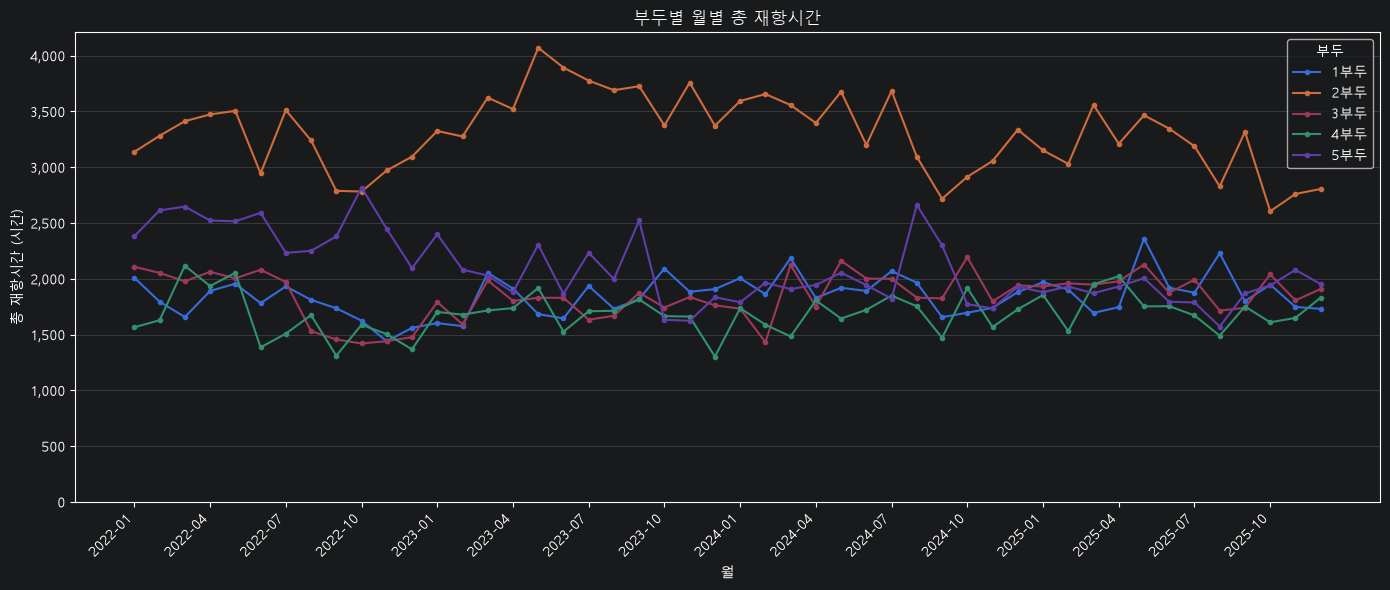

In [3]:
import pandas as pd

# CSV 파일을 파이썬 코드와 같은 폴더에 두세요.
df = pd.read_csv("../data/record.csv", encoding="utf-8-sig")
df.columns = df.columns.str.strip()

for col in ["입항일시", "출항일시"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

df["부두"] = df["계선장소"].str.extract(
    r"신항\s*([1-5])\s*부두", expand=False
)
df["재항시간"] = (
    df["출항일시"] - df["입항일시"]
).dt.total_seconds() / 3600

# 날짜 누락·변환 실패·음수 시간·대상 외 부두 제외
data = df.loc[
    df["재항시간"].ge(0) & df["부두"].notna()
].copy()

# 분석 기간: 종료 시각은 포함하지 않음
start = pd.Timestamp("2022-01-01")
end = pd.Timestamp("2026-01-01")

months = pd.date_range(start, end, freq="MS", inclusive="left")
result = pd.DataFrame(
    index=months, columns=list("12345"), dtype=float
)

for month in months:
    next_month = month + pd.offsets.MonthBegin(1)

    # 각 선박의 재항 구간 중 해당 월과 겹치는 시간
    hours = (
        data["출항일시"].clip(upper=next_month)
        - data["입항일시"].clip(lower=month)
    ).dt.total_seconds().div(3600).clip(lower=0)

    result.loc[month] = (
        hours.groupby(data["부두"]).sum()
        .reindex(list("12345"), fill_value=0)
    )

result.index = result.index.strftime("%Y-%m")
result.index.name = "월"
result.columns = result.columns + "부두"

print(result.round(2).to_string())

# 월별·부두별 추이 그래프
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

ax = result.plot(figsize=(14, 6), marker="o", markersize=3)
ax.set_title("부두별 월별 총 재항시간")
ax.set_xlabel("월")
ax.set_ylabel("총 재항시간 (시간)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="부두")
plt.xticks(rotation=45)
# 분기마다 날짜 표시
ticks = list(range(0, len(result), 3))
ax.set_xticks(ticks)
ax.set_xticklabels(
    result.index[ticks],
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

# 선석수

In [4]:
import pandas as pd

# 앞서 제공한 이미지 기준 선석 수
선석수 = {1: 3, 2: 6, 3: 4, 4: 4, 5: 4}

선석수표 = pd.DataFrame({
    "부두": list(선석수.keys()),
    "선석수": list(선석수.values())
})

print(선석수표.to_string(index=False))

 부두  선석수
  1    3
  2    6
  3    4
  4    4
  5    4


# 월별 부두가동률

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# 1. 설정
DATA_PATH = r"C:\work\Final_Project\Final_Project\data\port_month.csv"

START_YEAR = 2022
END_YEAR = 2025

# 연간 하역능력 참고값: TEU/년
# 실제 연도별 하역능력을 확보하면 수정하세요.
reference_capacity = {
    "1부두": 2_090_000,
    "2부두": 3_790_000,
    "3부두": 2_310_000,
    "4부두": 1_930_000,
    "5부두": 2_440_000
}

# 참고값을 2022~2025년 동일하게 적용하는 가정
capacity_by_year = {
    year: reference_capacity.copy()
    for year in range(START_YEAR, END_YEAR + 1)
}

# 2. 데이터 불러오기
df = pd.read_csv(DATA_PATH, encoding="cp949")
df.columns = df.columns.str.strip()

df = df.loc[
    df["기준년도"].between(START_YEAR, END_YEAR)
].copy()

if df.empty:
    raise ValueError("선택한 기간에 해당하는 자료가 없습니다.")

if df.duplicated(["기준년도", "월"]).any():
    raise ValueError("동일 연도·월의 중복 기록이 있습니다.")

if not df["단위"].astype(str).str.strip().eq("천TEU").all():
    raise ValueError("처리량 단위가 천TEU인지 확인하세요.")

# 3. 부두별 자료를 세로 형태로 변환
monthly = df.melt(
    id_vars=["기준년도", "월"],
    value_vars=[
        "신항1부두",
        "신항2부두",
        "신항3부두",
        "신항4부두",
        "신항5부두"
    ],
    var_name="부두",
    value_name="처리량_천TEU"
)

monthly["부두"] = monthly["부두"].str.replace(
    "신항", "", regex=False
)

monthly["기준월"] = pd.to_datetime({
    "year": monthly["기준년도"],
    "month": monthly["월"],
    "day": 1
})

# 천TEU → TEU
monthly["실제 처리실적(TEU)"] = (
    pd.to_numeric(monthly["처리량_천TEU"], errors="coerce")
    * 1000
)

# 4. 실제 달력 기준 월별·연간 일수
monthly["월 일수"] = monthly["기준월"].dt.days_in_month
monthly["연간 일수"] = (
    monthly["기준월"].dt.is_leap_year
    .map({True: 366, False: 365})
)

monthly["연간 하역능력(TEU)"] = monthly.apply(
    lambda row: capacity_by_year[int(row["기준년도"])][row["부두"]],
    axis=1
)

capacity = monthly["연간 하역능력(TEU)"]

if capacity.isna().any() or capacity.le(0).any():
    raise ValueError("연간 하역능력은 양수로 입력해야 합니다.")

# 5. 월별 환산 하역능력 및 가동률
monthly["월별 환산 하역능력(TEU)"] = (
    monthly["연간 하역능력(TEU)"]
    * monthly["월 일수"]
    / monthly["연간 일수"]
)

monthly["월별 부두가동률(%)"] = (
    monthly["실제 처리실적(TEU)"]
    / monthly["월별 환산 하역능력(TEU)"]
    * 100
)

# 6. 월별·부두별 결과 표
monthly_rate = monthly.pivot(
    index="기준월",
    columns="부두",
    values="월별 부두가동률(%)"
).reindex(columns=list(reference_capacity))

# 누락된 월은 0으로 채우지 않고 결측으로 유지
all_months = pd.date_range(
    f"{START_YEAR}-01-01",
    f"{END_YEAR}-12-01",
    freq="MS"
)

monthly_rate = monthly_rate.reindex(all_months)
monthly_rate.index = monthly_rate.index.strftime("%Y-%m")
monthly_rate.index.name = "월"

print(monthly_rate.round(2).to_string())

# 7. 라인그래프
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(15, 6))

for terminal in monthly_rate.columns:
    ax.plot(
        monthly_rate.index,
        monthly_rate[terminal],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=terminal
    )

# 분기 간격: 매년 1·4·7·10월
ticks = list(range(0, len(monthly_rate), 3))
ax.set_xticks(ticks)
ax.set_xticklabels(
    monthly_rate.index[ticks],
    rotation=45,
    ha="right"
)

ax.set_title("월별 부두가동률")
ax.set_xlabel("월")
ax.set_ylabel("부두가동률 (%)")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_ylim(bottom=0)

ax.axhline(
    100,
    color="gray",
    linestyle="--",
    linewidth=1,
    label="100% 기준"
)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)
ax.legend(ncol=6)

plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\work\\Final_Project\\Final_Project\\data\\port_month.csv'

# 1부두는 신항 1~5부두 중 가장 여유가 없다

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

# 1. 설정
DATA_PATH = r"C:\work\Final_Project\Final_Project\data\port_month.csv"

START_YEAR = 2019
END_YEAR = 2025

# 연간 하역능력 참고값: TEU/년
# 모든 연도에 동일하게 적용하는 가정
annual_capacity = pd.Series({
    "1": 2_090_000,
    "2": 3_790_000,
    "3": 2_310_000,
    "4": 1_930_000,
    "5": 2_440_000
})

# 2. 월별 처리량 불러오기
df = pd.read_csv(DATA_PATH, encoding="cp949")
df.columns = df.columns.str.strip()

df = df.loc[
    df["기준년도"].between(START_YEAR, END_YEAR)
].copy()

if df.duplicated(["기준년도", "월"]).any():
    raise ValueError("동일 연도·월의 중복 기록이 있습니다.")

if not df["단위"].astype(str).str.strip().eq("천TEU").all():
    raise ValueError("처리량 단위가 천TEU인지 확인하세요.")

years = list(range(START_YEAR, END_YEAR + 1))

month_counts = (
    df.groupby("기준년도")["월"]
    .nunique()
    .reindex(years, fill_value=0)
)

if not month_counts.eq(12).all():
    raise ValueError("12개월 자료가 없는 연도가 있습니다.")

columns = [f"신항{x}부두" for x in annual_capacity.index]

for col in columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 3. 월별 천TEU → 연간 TEU
annual_teu = (
    df.groupby("기준년도")[columns]
    .sum(min_count=12)
    .reindex(years)
    * 1000
)

if annual_teu.isna().any().any():
    raise ValueError("처리량에 누락된 값이 있습니다.")

annual_teu.columns = annual_capacity.index

# 연간 부두가동률
annual_rate = annual_teu.div(
    annual_capacity, axis="columns"
) * 100

print(annual_rate.round(2).to_string())

# 4. 그래프
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(11, 6))

colors = {
    "1": "#2878DC",
    "2": "#BEBFB6",
    "3": "#BEBFB6",
    "4": "#BEBFB6",
    "5": "#F46932"
}

for terminal in ["2", "3", "4", "5", "1"]:
    ax.plot(
        annual_rate.index,
        annual_rate[terminal],
        color=colors[terminal],
        marker="o",
        markersize=5,
        markeredgecolor="white",
        linewidth=2.5
    )

# 하역능력 100% 기준선
ax.axhline(100, color="#666666", linewidth=1.2)
ax.text(
    START_YEAR,
    101.5,
    "설정한 연간 하역능력 100%",
    fontsize=10,
    color="#555555"
)

# 마지막 연도의 1·5부두 값 표시
for terminal in ["1", "5"]:
    value = annual_rate.loc[END_YEAR, terminal]

    ax.text(
        END_YEAR + 0.15,
        value,
        f"{terminal}부두 {value:.0f}%",
        va="center",
        fontsize=11,
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            pad=1
        )
    )

# 범례
handles = [
    Line2D(
        [0], [0], color=colors["1"],
        marker="o", label="1부두"
    ),
    Line2D(
        [0], [0], color=colors["5"],
        marker="o", label="5부두"
    ),
    Line2D(
        [0], [0], color=colors["2"],
        marker="o", label="2·3·4부두"
    )
]

ax.legend(
    handles=handles,
    ncol=3,
    frameon=False,
    loc="upper left"
)

ax.set_title("연도별 부두가동률")
ax.set_xlabel("연도")
ax.set_ylabel("부두가동률 (%)")
ax.set_xticks(years)
ax.set_xlim(START_YEAR - 0.2, END_YEAR + 1.1)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)

for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

ax.spines["bottom"].set_color("#BBBBBB")

# 마지막 연도 값 표시: 소수점 없이 반올림
for terminal in ["1", "5"]:
    value = annual_rate.loc[END_YEAR, terminal]

    ax.annotate(
        f"{terminal}부두 {value:.0f}%",
        xy=(END_YEAR, value),
        xytext=(10, 0),
        textcoords="offset points",
        va="center",
        fontsize=11,
        color="black",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            pad=1
        )
    )

# 오른쪽 글자가 들어갈 공간 확보
ax.set_xlim(START_YEAR - 0.2, END_YEAR + 1.1)

plt.tight_layout()
plt.show()

# 1부두의 늘어난 재항시간은 늘어난 물량이었다

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# ── 1. 설정 ─────────────────────────────────────
RECORD_PATH = r"C:\work\Final_Project\Final_Project\data\record.csv"
PORT_PATH = r"C:\work\Final_Project\Final_Project\data\port_month.csv"

START_YEAR = 2022
END_YEAR = 2025
TERMINAL = "1"

years = list(range(START_YEAR, END_YEAR + 1))

# ── 2. 연간 처리 TEU 계산 ────────────────────────
port = pd.read_csv(PORT_PATH, encoding="cp949")
port.columns = port.columns.str.strip()

port = port.loc[
    port["기준년도"].between(START_YEAR, END_YEAR)
].copy()

# port_month.csv의 단위는 천TEU
teu_column = f"신항{TERMINAL}부두"

annual_teu = (
    port.groupby("기준년도")[teu_column]
    .sum(min_count=12)
    .reindex(years)
    * 1000
)

# ── 3. 입출항 기록 정리 ──────────────────────────
record = pd.read_csv(RECORD_PATH, encoding="utf-8-sig")
record.columns = record.columns.str.strip()

record["부두"] = record["계선장소"].str.extract(
    r"신항\s*([1-5])\s*부두",
    expand=False
)

record["입항"] = pd.to_datetime(
    record["입항일시"], errors="coerce"
)
record["출항"] = pd.to_datetime(
    record["출항일시"], errors="coerce"
)

valid = (
    record["부두"].eq(TERMINAL)
    & record["입항"].notna()
    & record["출항"].notna()
    & record["출항"].ge(record["입항"])
)

data = record.loc[valid].copy()

# ── 4. 연간 입항 척수 ────────────────────────────
# 한 행을 입항 한 건으로 집계
# 같은 배가 재방문하면 별도로 계산
annual_calls = (
    data.groupby(data["입항"].dt.year)
    .size()
    .reindex(years, fill_value=0)
)

# ── 5. 연간 선박 체류시간 합계 ───────────────────
# 재항시간 = 출항 - 입항
# 연도를 넘는 기록은 각 연도에 해당하는 시간으로 분할
annual_stay = {}

for year in years:
    start = pd.Timestamp(year=year, month=1, day=1)
    end = pd.Timestamp(year=year + 1, month=1, day=1)

    hours = (
        data["출항"].clip(upper=end)
        - data["입항"].clip(lower=start)
    ).dt.total_seconds().div(3600).clip(lower=0)

    annual_stay[year] = hours.sum()

annual_stay = pd.Series(annual_stay)

# ── 6. 연간 지표 정리 ────────────────────────────
summary = pd.DataFrame(index=years)
summary.index.name = "연도"

summary["연간 처리 TEU"] = annual_teu
summary["선박 체류시간 합계"] = annual_stay

# 전체 처리량 ÷ 선박별 재항시간 합계
summary["시간당 처리 TEU"] = (
    summary["연간 처리 TEU"]
    / summary["선박 체류시간 합계"].replace(0, float("nan"))
)

summary["입항 척수"] = annual_calls

# 참고용: 입항 1회당 처리량
summary["1척당 처리 TEU"] = (
    summary["연간 처리 TEU"]
    / summary["입항 척수"].replace(0, float("nan"))
)

print("연간 지표")
print(summary.round(2).to_string())

# ── 7. 2022년=100으로 지수화 ─────────────────────
graph_columns = [
    "연간 처리 TEU",
    "선박 체류시간 합계",
    "시간당 처리 TEU",
    "입항 척수"
]

base = summary.loc[START_YEAR, graph_columns]

if base.isna().any() or base.le(0).any():
    raise ValueError("기준 연도 지표가 누락되었거나 0 이하입니다.")

index_data = (
    summary[graph_columns]
    .div(base, axis="columns")
    * 100
)

print(f"\n지수 ({START_YEAR}년=100)")
print(index_data.round(2).to_string())

# ── 8. 라인그래프 ────────────────────────────────
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(12, 6))

colors = {
    "연간 처리 TEU": "#2878DC",
    "선박 체류시간 합계": "#FF6535",
    "시간당 처리 TEU": "#10B981",
    "입항 척수": "#F2A000"
}

for column in graph_columns:
    ax.plot(
        index_data.index,
        index_data[column],
        color=colors[column],
        marker="o",
        markersize=5,
        markeredgecolor="white",
        linewidth=2.3,
        label=column
    )

    # 마지막 연도 값 표시
    value = index_data.loc[END_YEAR, column]

    ax.annotate(
        f"{column} {value:.0f}",
        xy=(END_YEAR, value),
        xytext=(10, 0),
        textcoords="offset points",
        va="center",
        fontsize=10
    )

# 기준 연도 100선
ax.axhline(
    100,
    color="#AAAAAA",
    linewidth=1,
    zorder=0
)

ax.set_title(
    f"{TERMINAL}부두 주요 지표 추이",
    fontsize=15
)
ax.set_ylabel(f"{START_YEAR}년=100")
ax.set_xticks(years)
ax.set_xlim(START_YEAR - 0.2, END_YEAR + 1.15)

# 지수이므로 % 기호를 붙이지 않음
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.0f}"))

ax.set_ylim(
    min(85, index_data.min().min() - 5),
    max(120, index_data.max().max() + 5)
)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)

for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

ax.spines["bottom"].set_color("#BBBBBB")
ax.tick_params(axis="both", length=0)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=4,
    frameon=False
)

plt.tight_layout()
plt.show()

# 1부두 전체 선석점유율

# 1부두 평균재항시간

In [ ]:
import pandas as pd

df = pd.read_csv(
    r"C:\work\Final_Project\Final_Project\data\record.csv",
    encoding="utf-8-sig"
)
df.columns = df.columns.str.strip()

df["부두"] = df["계선장소"].str.extract(
    r"신항\s*([1-5])\s*부두",
    expand=False
)

df["입항"] = pd.to_datetime(df["입항일시"], errors="coerce")
df["출항"] = pd.to_datetime(df["출항일시"], errors="coerce")

data = df.loc[
    df["부두"].eq("1")
    & df["입항"].ge("2022-01-01")
    & df["입항"].lt("2026-01-01")
    & df["출항"].ge(df["입항"])
].copy()

# 실제 출항까지의 재항시간
data["재항시간"] = (
    data["출항"] - data["입항"]
).dt.total_seconds() / 3600

print(f"입항 기록 수: {len(data):,}건")
print(f"1부두 평균 재항시간: {data['재항시간'].mean():.2f}시간")

# 1부두 평균추정대기시간

In [ ]:
import pandas as pd

df = pd.read_csv(
    r"C:\work\Final_Project\Final_Project\data\record.csv",
    encoding="utf-8-sig"
)
df.columns = df.columns.str.strip()

df[["부두", "선석"]] = df["계선장소"].str.extract(
    r"신항\s*([1-5])\s*부두\s*(\d+)\s*선석"
)

df["입항"] = pd.to_datetime(df["입항일시"], errors="coerce")
df["출항"] = pd.to_datetime(df["출항일시"], errors="coerce")

data = df.loc[
    df["부두"].eq("1")
    & df[["선석", "입항", "출항"]].notna().all(axis=1)
    & df["출항"].ge(df["입항"])
].copy()

# 기간 필터링 전에 같은 선석의 직전 선박 확인
data = data.sort_values(
    ["부두", "선석", "입항"],
    kind="stable"
)

data["앞배_출항"] = (
    data.groupby(["부두", "선석"])["출항"].shift()
)

# 추정대기 = max(0, 직전 선박 출항 - 현재 선박 입항)
data["추정대기시간"] = (
    (data["앞배_출항"] - data["입항"])
    .dt.total_seconds()
    .div(3600)
    .clip(lower=0)
    .fillna(0)
)

data = data.loc[
    data["입항"].ge("2022-01-01")
    & data["입항"].lt("2026-01-01")
].copy()

print(f"입항 기록 수: {len(data):,}건")
print(f"1부두 총 추정대기시간: {data['추정대기시간'].sum():.2f}시간")
print(f"1부두 평균 추정대기시간: {data['추정대기시간'].mean():.2f}시간")

In [ ]:
import pandas as pd

df = pd.read_csv("../data/port1.csv", encoding="utf-8-sig")

df.head()

# 부두별 선석별 평균작업시간

4부두: 오류·누락 1건 제외

2022~2025년 부두별·선석별 평균 작업시간
 부두  선석  기록수  평균작업시간_시간
  1   1 1110      22.96
  1   2  975      28.45
  1   3  843      34.93
  2   4 1710      17.53
  2   5 1536      19.70
  2   6 1303      23.73
  2   7 1136      27.36
  2   8 1041      30.11
  3   1 1244      23.74
  3   2 1332      16.49
  3   3  740      29.51
  3   4  456      19.21
  4   1 1069      19.18
  4   2 1135      23.45
  4   3 1215      22.62
  5   1 1362      21.60
  5   2 1074      26.04
  5   3  372      20.64
  5   4 1064      25.33


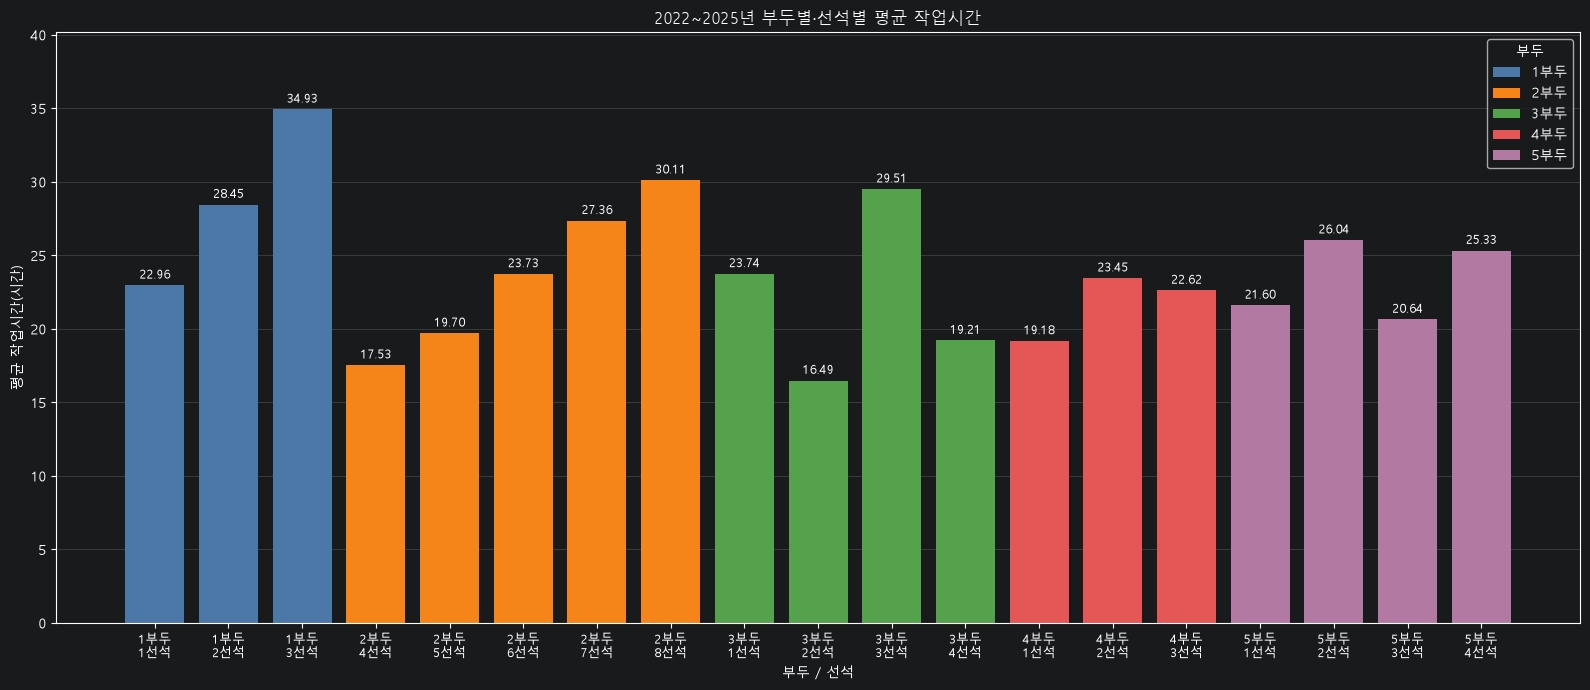

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# 1. 한글 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 2. 파일 불러오기
DATA_DIR = r"C:\work\Final_Project\data"

port1 = pd.read_csv(DATA_DIR + "/port1.csv", encoding="utf-8-sig")
port2 = pd.read_csv(DATA_DIR + "/port2.csv", encoding="cp949")
port3 = pd.read_csv(DATA_DIR + "/port3.csv", encoding="cp949")
port4 = pd.read_csv(DATA_DIR + "/port4.csv", encoding="cp949")
port5 = pd.read_csv(DATA_DIR + "/port5.csv", encoding="cp949")

START = pd.Timestamp("2022-01-01")
END = pd.Timestamp("2026-01-01")

ports = [
    (1, port1),
    (2, port2),
    (3, port3),
    (4, port4),
    (5, port5),
]

frames = []

# 3. 작업시간 계산
for number, port in ports:
    data = port.copy()

    data = data.rename(columns={
        "접안(예정)일시": "접안시각",
        "출항(예정)일시": "출항시각",
    })

    for col in ["접안시각", "출항시각"]:
        data[col] = pd.to_datetime(
            data[col],
            format="%Y-%m-%d %H:%M",
            errors="raise",
        )

    # 시각·선석 누락 또는 출항이 접안보다 빠른 기록 제외
    invalid = (
        data[["접안시각", "출항시각", "선석"]].isna().any(axis=1)
        | (data["출항시각"] < data["접안시각"])
    )

    if invalid.any():
        print(f"{number}부두: 오류·누락 {invalid.sum()}건 제외")

    data = data.loc[~invalid].copy()
    data["부두"] = number

    # 2022~2025년에 포함되는 구간만 계산
    work_start = data["접안시각"].clip(lower=START)
    work_end = data["출항시각"].clip(upper=END)

    # 작업시간 = 출항 - 접안 (시간 단위)
    data["작업시간_시간"] = (
        work_end - work_start
    ).dt.total_seconds() / 3600

    data = data.loc[data["작업시간_시간"] > 0]

    frames.append(data[["부두", "선석", "작업시간_시간"]])

# 4. 부두별·선석별 평균 작업시간
detail = pd.concat(frames, ignore_index=True)

result = (
    detail.groupby(["부두", "선석"], as_index=False)
    .agg(
        기록수=("작업시간_시간", "count"),
        평균작업시간_시간=("작업시간_시간", "mean"),
    )
    .sort_values(["부두", "선석"])
)

print("\n2022~2025년 부두별·선석별 평균 작업시간")
print(result.round(2).to_string(index=False))

# 5. 평균 작업시간 바그래프
labels = (
    result["부두"].astype(str) + "부두\n"
    + result["선석"].astype(str) + "선석"
)

port_colors = {
    1: "#4C78A8",
    2: "#F58518",
    3: "#54A24B",
    4: "#E45756",
    5: "#B279A2",
}

fig, ax = plt.subplots(figsize=(16, 7))

bars = ax.bar(
    labels,
    result["평균작업시간_시간"],
    color=result["부두"].map(port_colors),
)

ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)

ax.set_title("2022~2025년 부두별·선석별 평균 작업시간")
ax.set_xlabel("부두 / 선석")
ax.set_ylabel("평균 작업시간(시간)")
ax.set_ylim(0, result["평균작업시간_시간"].max() * 1.15)
ax.tick_params(axis="x", labelsize=9)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)

ax.legend(
    handles=[
        Patch(facecolor=color, label=f"{number}부두")
        for number, color in port_colors.items()
    ],
    title="부두",
)

plt.tight_layout()
plt.show()